# PROJECT 1: SMART CITY TRAFFIC FLOW SIMULATOR

## 1. Introduction
Traffic congestion is a major problem in smart cities. Analyzing vehicle counts at different junctions and times of day can help identify high-traffic periods and potential bottlenecks.

This project simulates 30 days of hourly vehicle counts across 10 junctions using Python and NumPy. It analyzes traffic patterns, identifies peak hours, visualizes congestion using a heatmap, and compares loop-based and vectorized execution.

## 2. Objectives
- Simulate hourly traffic counts for 30 days and 10 junctions.
- Model morning and evening rush-hour peaks.
- Use NumPy aggregation and `argmax()` to identify peak traffic hours and high-volume junctions.
- Visualize traffic patterns using graphs and a heatmap.
- Compare vectorized and loop-based implementations.

## 3. Tools and Technologies
- Python
- NumPy
- Matplotlib
- Google Colab

## 4. Dataset Description
The dataset is synthetically generated using a Poisson distribution.

- Number of days: 30
- Number of junctions: 10
- Hours per day: 24
- Total observations: 7,200
- Array shape: (30, 10, 24)

**Cell 2 — Code cell (Import libraries and generate rush-hour curve)**

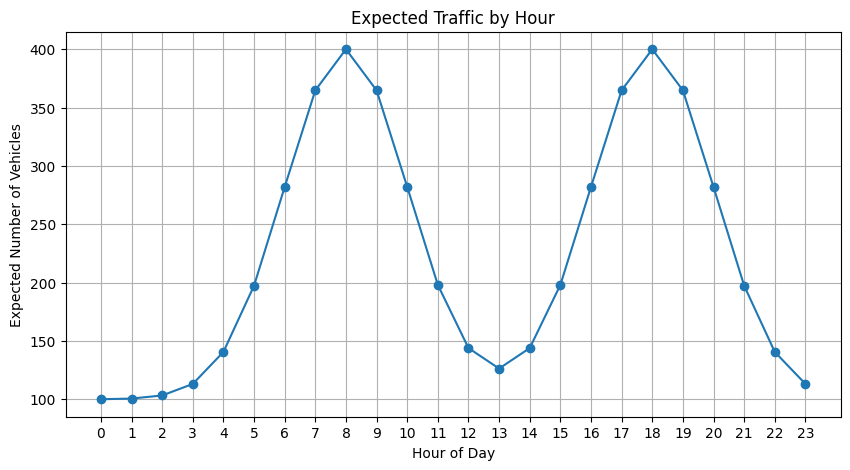

In [6]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Generate hours from 0 to 23
h = np.arange(24)

# Model morning and evening rush-hour peaks
rush = (
    np.exp(-(h - 8)**2 / 8)
    + np.exp(-(h - 18)**2 / 8)
)

# Expected vehicle count for each hour
lam = 100 + 300 * rush

# Plot the expected traffic pattern
plt.figure(figsize=(10, 5))
plt.plot(h, lam, marker="o")
plt.title("Expected Traffic by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Expected Number of Vehicles")
plt.xticks(range(24))
plt.grid(True)
plt.show()

## 5. Traffic Data Simulation

The Poisson distribution is used to generate random vehicle counts. The resulting three-dimensional NumPy array represents days, junctions, and hours.

The random seed ensures reproducible results when the notebook is executed with the same code and random-number generator state.

In [7]:
# Cell 4 — Code cell (Generate traffic data)

In [8]:
days = 30
junctions = 10
hours = 24

# Simulate hourly vehicle counts
data = np.random.poisson(
    lam,
    size=(days, junctions, hours)
)

print("Dataset Shape:", data.shape)
print("Total Observations:", data.size)
print("Average Vehicle Count:", round(data.mean(), 2))
print("Minimum Vehicle Count:", data.min())
print("Maximum Vehicle Count:", data.max())

Dataset Shape: (30, 10, 24)
Total Observations: 7200
Average Vehicle Count: 225.14
Minimum Vehicle Count: 72
Maximum Vehicle Count: 477


Cell 5 — Code cell (Find peak hours and bottlenecks)

In [9]:
# Average traffic for each hour
hourly_avg = data.mean(axis=(0, 1))

# Average traffic for each junction
junction_avg = data.mean(axis=(0, 2))

# Identify the busiest hour and junction
peak_hour = hourly_avg.argmax()
bottleneck = junction_avg.argmax()

print("Busiest Hour:", peak_hour, ":00")
print("Average Traffic During Busiest Hour:",
      round(hourly_avg[peak_hour], 2))

print("\nHighest-Volume Junction: Junction", bottleneck + 1)
print("Average Hourly Traffic at This Junction:",
      round(junction_avg[bottleneck], 2))

# Rank junctions by average traffic
ranking = np.argsort(junction_avg)[::-1]

print("\nJunction Ranking:")
for j in ranking:
    print(f"Junction {j + 1}: {junction_avg[j]:.2f} vehicles/hour")

Busiest Hour: 8 :00
Average Traffic During Busiest Hour: 400.75

Highest-Volume Junction: Junction 7
Average Hourly Traffic at This Junction: 225.46

Junction Ranking:
Junction 7: 225.46 vehicles/hour
Junction 5: 225.40 vehicles/hour
Junction 6: 225.38 vehicles/hour
Junction 8: 225.27 vehicles/hour
Junction 4: 225.15 vehicles/hour
Junction 3: 225.10 vehicles/hour
Junction 9: 225.06 vehicles/hour
Junction 1: 225.01 vehicles/hour
Junction 10: 224.95 vehicles/hour
Junction 2: 224.59 vehicles/hour


**Cell 6 — Text cell (Data visualization)**

## 6. Traffic Heatmap

A heatmap represents average vehicle counts for each junction at each hour. It helps visualize morning and evening traffic peaks and compare traffic levels across junctions.

**Cell 7 — Code cell (Create the heatmap)**

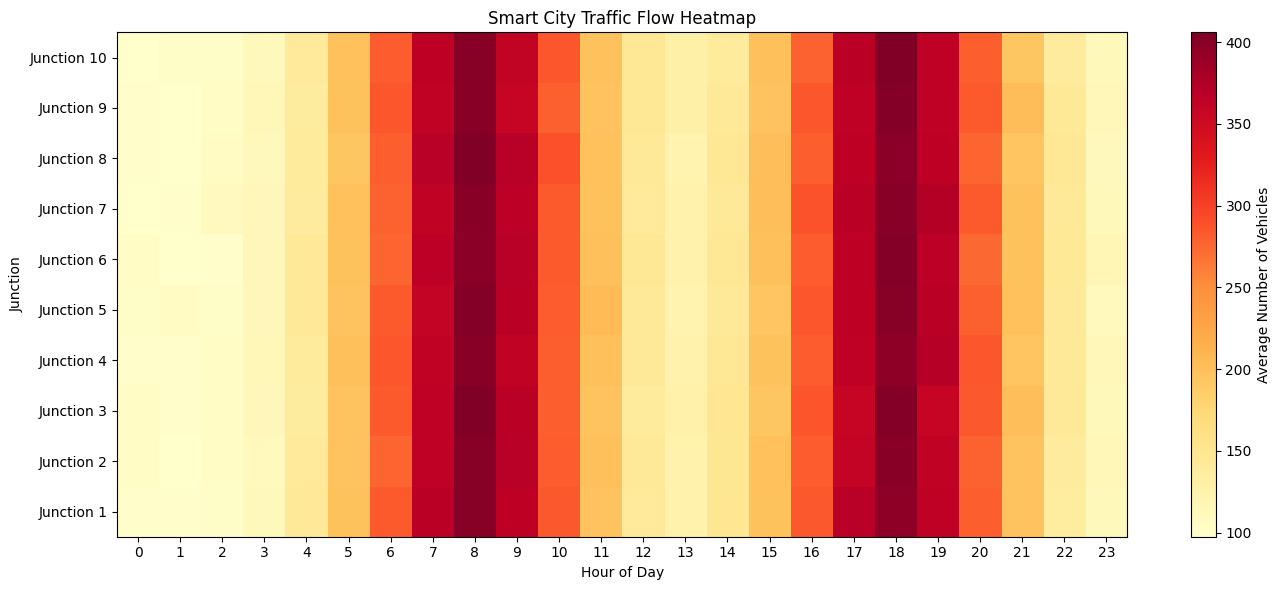

In [10]:
# Average traffic by junction and hour
heatmap_data = data.mean(axis=0)

plt.figure(figsize=(14, 6))

plt.imshow(
    heatmap_data,
    aspect="auto",
    cmap="YlOrRd",
    origin="lower"
)

plt.colorbar(label="Average Number of Vehicles")
plt.title("Smart City Traffic Flow Heatmap")
plt.xlabel("Hour of Day")
plt.ylabel("Junction")
plt.xticks(range(24), range(24))
plt.yticks(range(10), [f"Junction {i+1}" for i in range(10)])
plt.tight_layout()
plt.show()

Cell 8 — Code cell (Compare traffic at junctions)

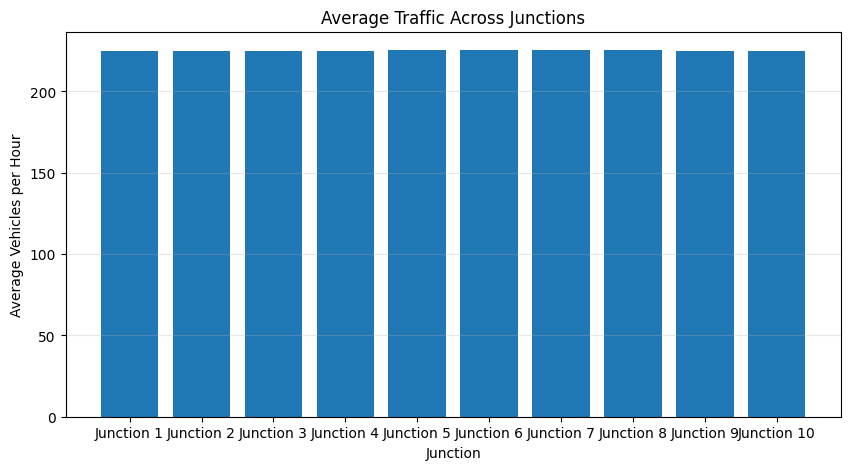

In [11]:
plt.figure(figsize=(10, 5))

plt.bar(
    [f"Junction {i+1}" for i in range(junctions)],
    junction_avg
)

plt.title("Average Traffic Across Junctions")
plt.xlabel("Junction")
plt.ylabel("Average Vehicles per Hour")
plt.grid(axis="y", alpha=0.3)
plt.show()

**Cell 9 — Text cell (Performance benchmarking)**

## 7. Performance Benchmarking

Vectorization allows NumPy to process entire arrays without explicitly writing a Python loop for every observation. The `%timeit` command measures execution time to compare vectorized and loop-based traffic generation.

**Cell 10 — Code cell (Benchmark loop vs vectorized)**

In [12]:
def vectorized_traffic():
    return np.random.poisson(
        lam,
        size=(30, 10, 24)
    )

def loop_traffic():
    result = np.empty((30, 10, 24), dtype=int)

    for d in range(30):
        for j in range(10):
            for hour in range(24):
                result[d, j, hour] = np.random.poisson(
                    lam[hour]
                )

    return result

In [13]:
print("Vectorized Execution Time:")
%timeit vectorized_traffic()

print("\nLoop-Based Execution Time:")
%timeit loop_traffic()

Vectorized Execution Time:
626 µs ± 54.7 µs per loop (mean ± std. dev. of 7 runs, 1000 loops each)

Loop-Based Execution Time:
14 ms ± 2.87 ms per loop (mean ± std. dev. of 7 runs, 100 loops each)


**Cell 11 — Text cell (Findings and conclusion)**

## 8. Findings

1. A total of 7,200 hourly vehicle-count observations were generated.
2. Morning and evening rush-hour patterns were modeled using exponential curves.
3. NumPy axis-wise aggregation was used to calculate average traffic by hour and junction.
4. The `argmax()` function identified the hour and junction with the highest average traffic.
5. Heatmap and bar-chart visualizations helped compare traffic patterns.
6. `%timeit` was used to benchmark vectorized and loop-based implementations.

## 9. Conclusion

The Smart City Traffic Flow Simulator demonstrates how Python and NumPy can be used to generate, analyze, and visualize traffic data. The project applies Poisson random sampling, multidimensional arrays, axis-wise aggregation, vectorization, and performance benchmarking.

The results illustrate how traffic patterns and potential high-volume junctions can be identified computationally.

**Limitation:** This project uses simulated data rather than real traffic measurements. High vehicle volume alone does not establish a real traffic bottleneck; road capacity and actual traffic observations would also be needed.

## 10. Future Scope

- Use real traffic data from city junctions.
- Include different road capacities and traffic-light timings.
- Simulate weekdays and weekends separately.
- Develop a dashboard for monitoring traffic patterns.
- Explore traffic prediction using machine learning.

## 11. Resume Description

**Smart City Traffic Flow Simulator | Python, NumPy, Matplotlib**

Developed a reproducible NumPy-based traffic simulator generating 7,200 hourly vehicle-count observations across 10 junctions over 30 days. Applied axis-wise aggregation and `argmax()` to identify peak traffic periods and high-volume junctions, visualized traffic patterns using heatmaps, and benchmarked vectorized versus loop-based implementations.